# Decision Tree - Student Placement Prediction

## 1: Data Cleaning & Splitting


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib
from sklearn.tree import DecisionTreeClassifier


In [2]:
# Load Dataset
candidates = [
    'student_placement_prediction_dataset_2026.csv',
    '../student_placement_prediction_dataset_2026.csv',
    'ml_source/student_placement_prediction_dataset_2026.csv',
]
dataset_path = next((p for p in candidates if os.path.exists(p)), 'student_placement_prediction_dataset_2026.csv')
df = pd.read_csv(dataset_path)
df.head()


,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,...,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,...,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Placed,19.65
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,...,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,...,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,17.04
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,...,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,...,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Not Placed,0.00


In [3]:
df.columns


Index(['student_id', 'age', 'gender', 'cgpa', 'branch', 'college_tier',
       'internships_count', 'projects_count', 'certifications_count',
       'coding_skill_score', 'aptitude_score', 'communication_skill_score',
       'logical_reasoning_score', 'hackathons_participated', 'github_repos',
       'linkedin_connections', 'mock_interview_score', 'attendance_percentage',
       'backlogs', 'extracurricular_score', 'leadership_score',
       'volunteer_experience', 'sleep_hours', 'study_hours_per_day',
       'placement_status', 'salary_package_lpa'],
      dtype='str')

In [4]:
df.describe()


,student_id,age,cgpa,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,...,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,sleep_hours,study_hours_per_day,salary_package_lpa
count,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000
mean,50000.500000,21.005740,7.496890,1.50223,3.001860,2.005150,69.825326,64.988108,67.960744,65.931696,...,4.005160,524.559110,69.989411,84.730169,0.497590,59.894049,54.937526,6.983319,3.523124,9.23698
std,28867.657797,1.999562,0.992834,1.22528,1.731764,1.416553,14.694618,14.844093,13.846636,14.826790,...,2.004897,274.993479,11.937257,9.416075,0.708434,19.549666,19.781197,1.468113,1.471248,8.45396
min,1.000000,18.000000,4.500000,0.00000,0.000000,0.000000,20.000000,20.000000,20.000000,20.000000,...,0.000000,50.000000,20.000000,50.000000,0.000000,0.000000,0.000000,3.000000,0.500000,0.00000
25%,25000.750000,19.000000,6.820000,1.00000,2.000000,1.000000,59.807945,54.894600,58.587535,55.940547,...,3.000000,287.000000,61.973172,78.325833,0.000000,46.538590,41.432390,6.000000,2.500000,0.00000
50%,50000.500000,21.000000,7.500000,1.00000,3.000000,2.000000,70.006250,65.011394,67.973221,66.003829,...,4.000000,523.000000,70.026665,85.018828,0.000000,60.079021,55.076210,7.000000,3.500000,14.60000
75%,75000.250000,23.000000,8.180000,2.00000,4.000000,3.000000,80.058762,75.079266,77.503749,76.113705,...,5.000000,764.000000,78.122083,91.782511,1.000000,73.549567,68.530115,8.000000,4.500000,16.87000
max,100000.000000,24.000000,10.000000,8.00000,13.000000,11.000000,100.000000,100.000000,100.000000,100.000000,...,16.000000,999.000000,100.000000,100.000000,6.000000,100.000000,100.000000,10.000000,10.000000,24.68000


In [5]:
df.shape


(100000, 26)

In [6]:
df.isnull().sum()


student_id                   0
age                          0
gender                       0
cgpa                         0
branch                       0
college_tier                 0
internships_count            0
projects_count               0
certifications_count         0
coding_skill_score           0
aptitude_score               0
communication_skill_score    0
logical_reasoning_score      0
hackathons_participated      0
github_repos                 0
linkedin_connections         0
mock_interview_score         0
attendance_percentage        0
backlogs                     0
extracurricular_score        0
leadership_score             0
volunteer_experience         0
sleep_hours                  0
study_hours_per_day          0
placement_status             0
salary_package_lpa           0
dtype: int64

In [7]:
# Convert target to 0 and 1
if df['placement_status'].dtype == object or df['placement_status'].dtype == 'string':
    df['placement_status'] = df['placement_status'].map({'Not Placed': 0, 'Placed': 1})

# Feature Engineering (Domain Indicators)
df['academic_clearance_score'] = df['cgpa'] * np.exp(-0.30 * df['backlogs'])
df['has_zero_backlogs'] = (df['backlogs'] == 0).astype(int)
df['technical_mastery'] = 0.40 * df['coding_skill_score'] + 0.25 * df['aptitude_score'] + 0.20 * df['logical_reasoning_score'] + 0.15 * df['mock_interview_score']
df['experience_index'] = df['internships_count'] * 3.5 + df['projects_count'] * 1.5 + df['hackathons_participated'] * 1.5 + df['certifications_count'] * 0.8
df['placement_readiness_score'] = 0.35 * (df['academic_clearance_score'] * 10) + 0.35 * df['technical_mastery'] + 0.20 * np.clip(df['experience_index'] * 5, 0, 100) + 0.10 * df['attendance_percentage']

# Features and Target
X = df.drop(columns=['student_id', 'placement_status', 'salary_package_lpa'])
X = pd.get_dummies(X, drop_first=True)
y = df['placement_status']

print('Features:')
print(X.columns)

print('\nTarget:')
print(y.name)

print('\nTarget Class Distribution:\n')
print(y.value_counts())


Features:
Index(['age', 'cgpa', 'internships_count', 'projects_count',
       'certifications_count', 'coding_skill_score', 'aptitude_score',
       'communication_skill_score', 'logical_reasoning_score',
       'hackathons_participated', 'github_repos', 'linkedin_connections',
       'mock_interview_score', 'attendance_percentage', 'backlogs',
       'extracurricular_score', 'leadership_score', 'sleep_hours',
       'study_hours_per_day', 'academic_clearance_score', 'has_zero_backlogs',
       'technical_mastery', 'experience_index', 'placement_readiness_score',
       'gender_Male', 'branch_Civil', 'branch_ECE', 'branch_EEE', 'branch_IT',
       'branch_Mechanical', 'college_tier_Tier 2', 'college_tier_Tier 3',
       'volunteer_experience_Yes'],
      dtype='str')

Target:
placement_status

Target Class Distribution:

placement_status
1    54995
0    45005
Name: count, dtype: int64


C:\Users\hp\AppData\Local\Temp\ipykernel_34536\2105497808.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=y, palette=['#ef4444', '#10b981'])


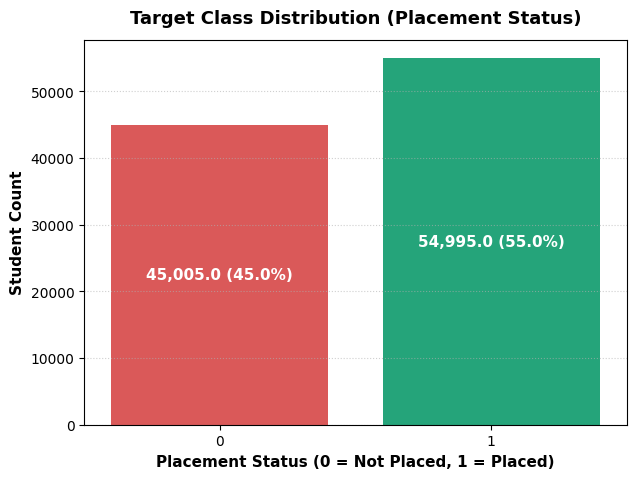

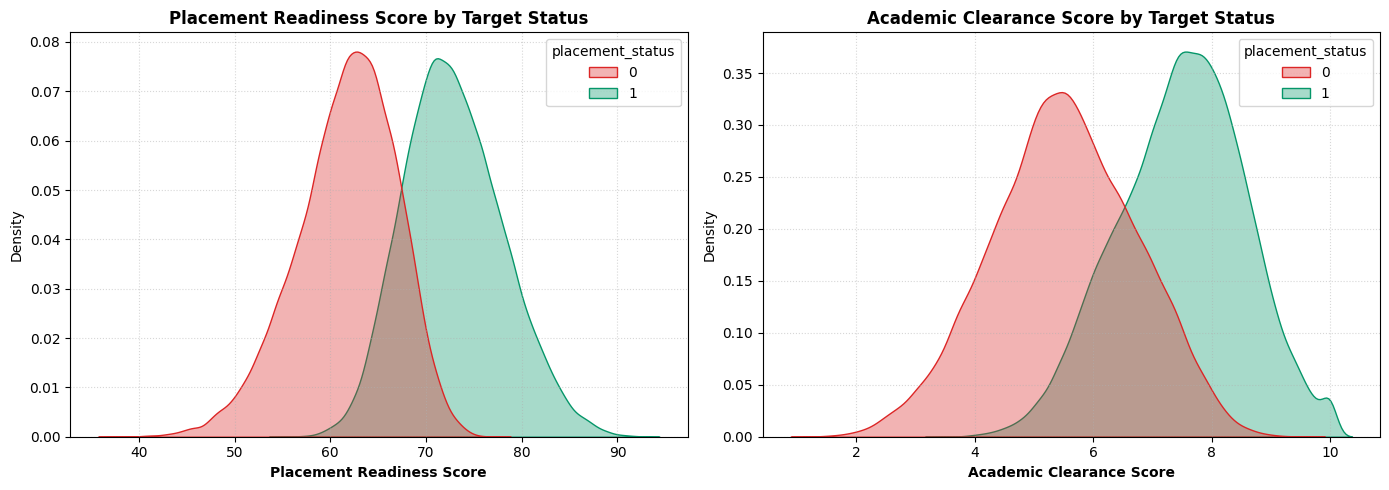

In [8]:
# EDA 1: Target Class Distribution with Percentages
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=y, palette=['#ef4444', '#10b981'])
total = len(y)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:,} ({height/total*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')
plt.title('Target Class Distribution (Placement Status)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Placement Status (0 = Not Placed, 1 = Placed)', fontsize=11, fontweight='bold')
plt.ylabel('Student Count', fontsize=11, fontweight='bold')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

# EDA 2: Key Engineered Feature Distributions by Placement Status
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(data=df, x='placement_readiness_score', hue='placement_status', common_norm=False, fill=True,
            palette=['#dc2626', '#059669'], alpha=0.35, ax=axes[0])
axes[0].set_title('Placement Readiness Score by Target Status', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Placement Readiness Score', fontweight='bold')
axes[0].grid(True, linestyle=':', alpha=0.5)

sns.kdeplot(data=df, x='academic_clearance_score', hue='placement_status', common_norm=False, fill=True,
            palette=['#dc2626', '#059669'], alpha=0.35, ax=axes[1])
axes[1].set_title('Academic Clearance Score by Target Status', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Academic Clearance Score', fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


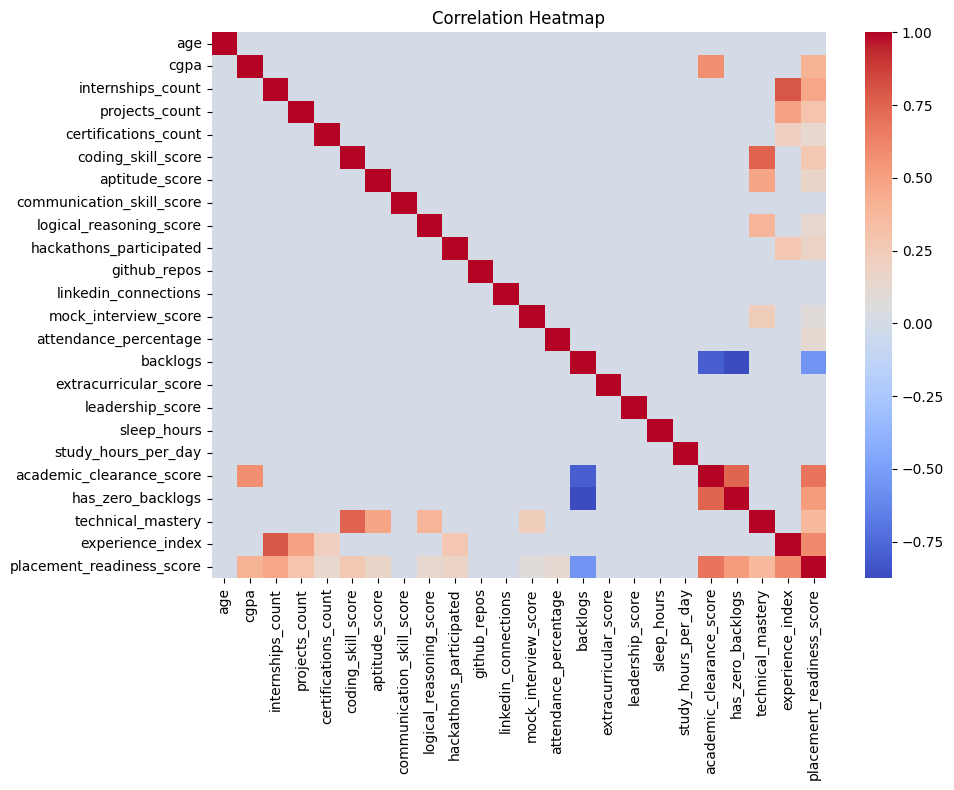

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.select_dtypes(include=[np.number]).corr(), annot=False, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Training data shape:', X_train.shape)
print('Testing data shape:', X_test.shape)
print('Training labels:', y_train.shape)
print('Testing labels:', y_test.shape)


Training data shape: (80000, 33)
Testing data shape: (20000, 33)
Training labels: (80000,)
Testing labels: (20000,)


## 2: Decision Tree Model


In [11]:
model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=8,
    min_samples_leaf=20,
    random_state=42
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})
results.head(15)


,Actual,Predicted
0,1,1
1,0,0
2,0,0
3,0,0
4,0,0
5,1,0
6,1,1
7,1,1
8,0,0
9,0,1


Accuracy: 91.36 %

Classification Report:

              precision    recall  f1-score   support

  Not Placed       0.90      0.90      0.90      9001
      Placed       0.92      0.92      0.92     10999

    accuracy                           0.91     20000
   macro avg       0.91      0.91      0.91     20000
weighted avg       0.91      0.91      0.91     20000



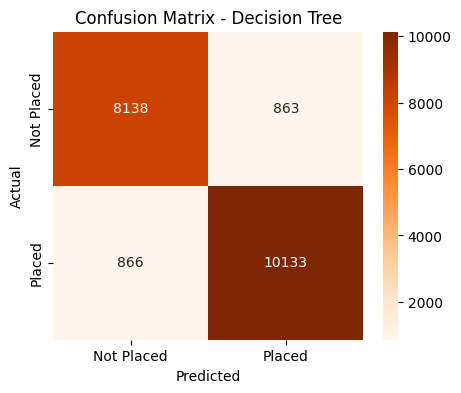

In [12]:
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy:', round(accuracy * 100, 2), '%')

print('\nClassification Report:\n')
print(classification_report(y_test, y_pred, target_names=['Not Placed', 'Placed']))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Not Placed', 'Placed'], yticklabels=['Not Placed', 'Placed'])
plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


In [13]:
# Predict on a sample student from test set
sample = X_test.iloc[0].values.reshape(1, -1)
prediction = model.predict(sample)[0]
probability = model.predict_proba(sample)[0][1]

print('Predicted Class:', prediction)
print(f'Placement Probability: {probability * 100:.2f}%')
if prediction == 1:
    print('Placement Status: Placed')
else:
    print('Placement Status: Not Placed')


Predicted Class: 1
Placement Probability: 54.42%
Placement Status: Placed


C:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [14]:
# Save Model
joblib.dump(model, 'decision_tree.pkl')
print('Model saved as decision_tree.pkl')


Model saved as decision_tree.pkl


## 3: Decision Tree Visualizations — Tree Structure & Partitioning Graphs

To understand the internal logic of the **Decision Tree Classifier**, we visualize:
1. **Hierarchical Decision Tree Structure (`plot_tree`)**: Visualizes the top 3 depths of the trained decision tree, detailing the split features, threshold values, entropy reduction, sample counts, and class predictions at each node.
2. **2D Recursive Partitioning Boundary**: Demonstrates how axis-aligned orthogonal split lines partition the 2D feature space (`academic_clearance_score` vs `placement_readiness_score`).
3. **Feature Importance Ranking**: Quantifies the percentage contribution of each feature toward reducing impurity (entropy).


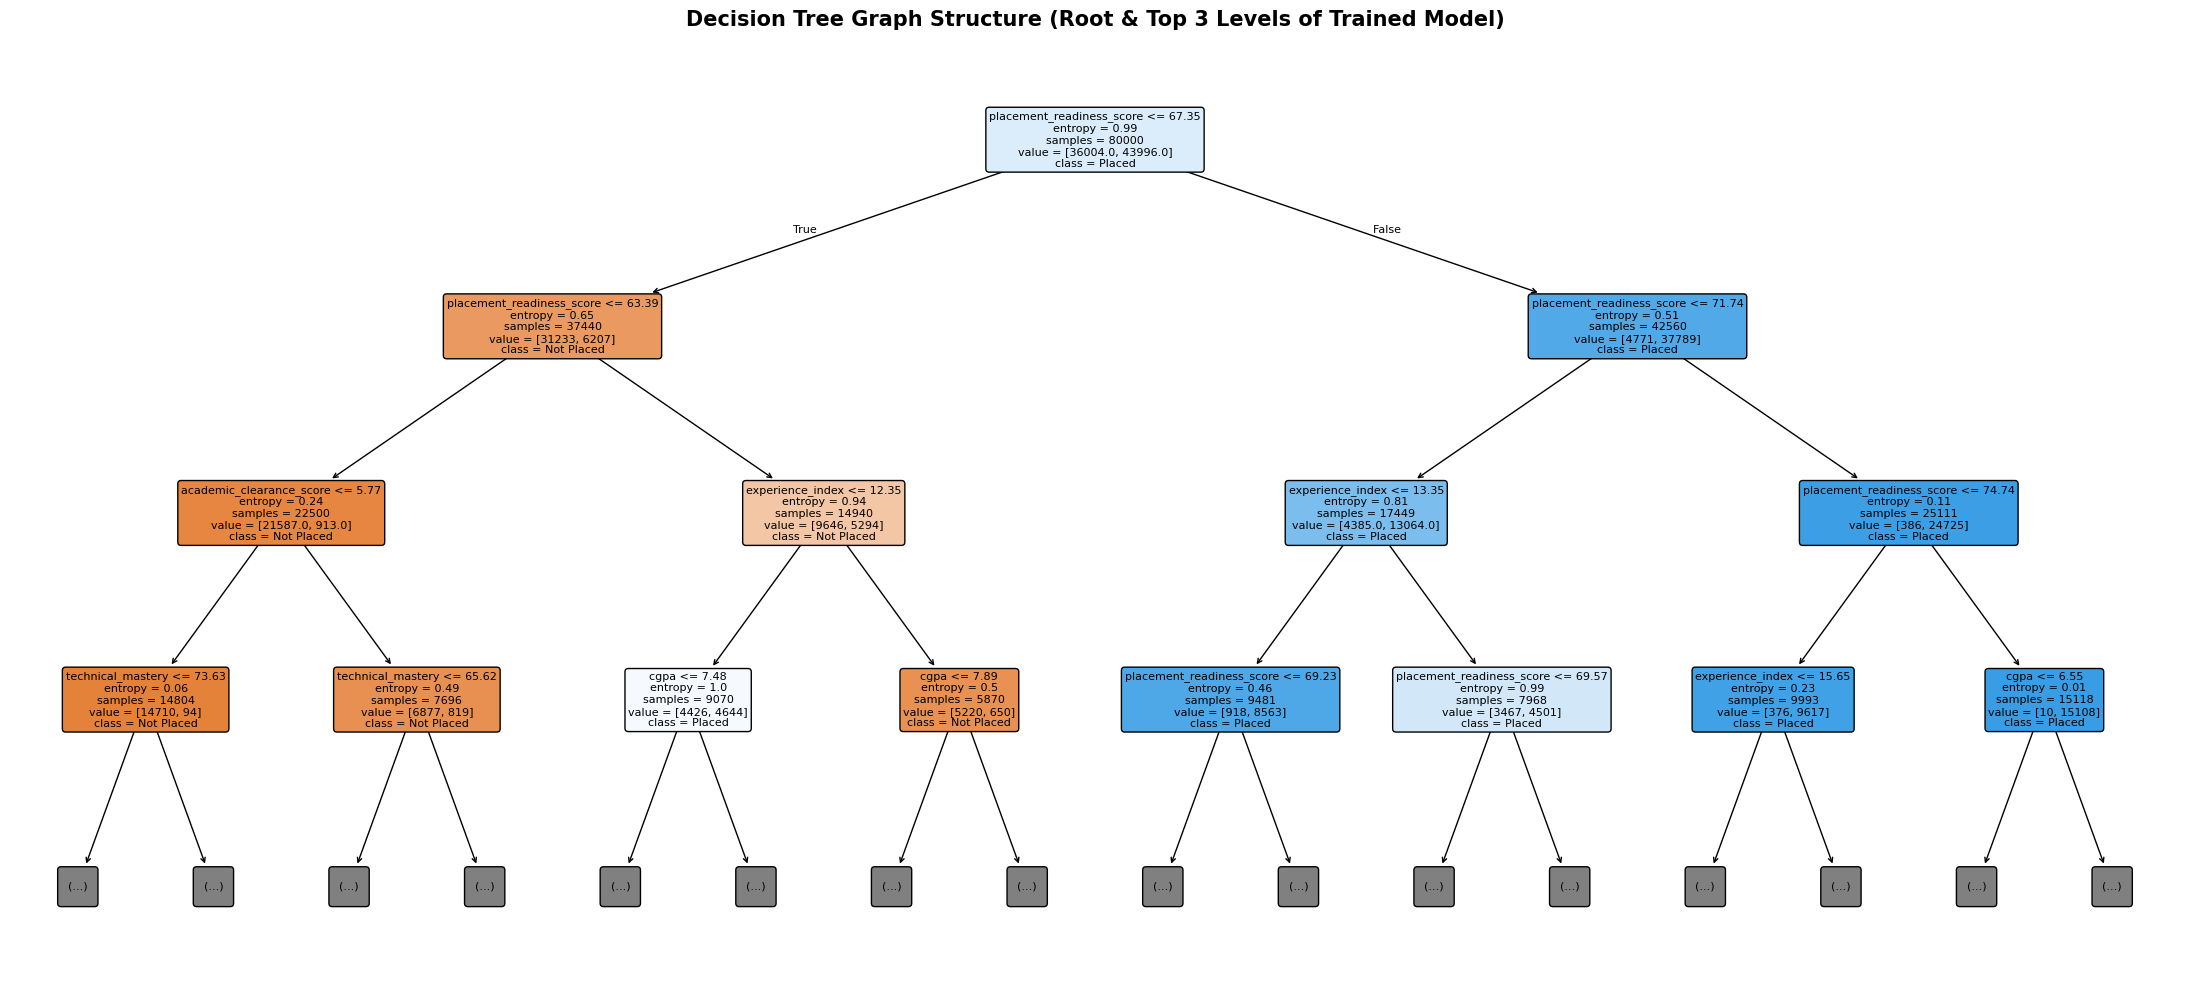

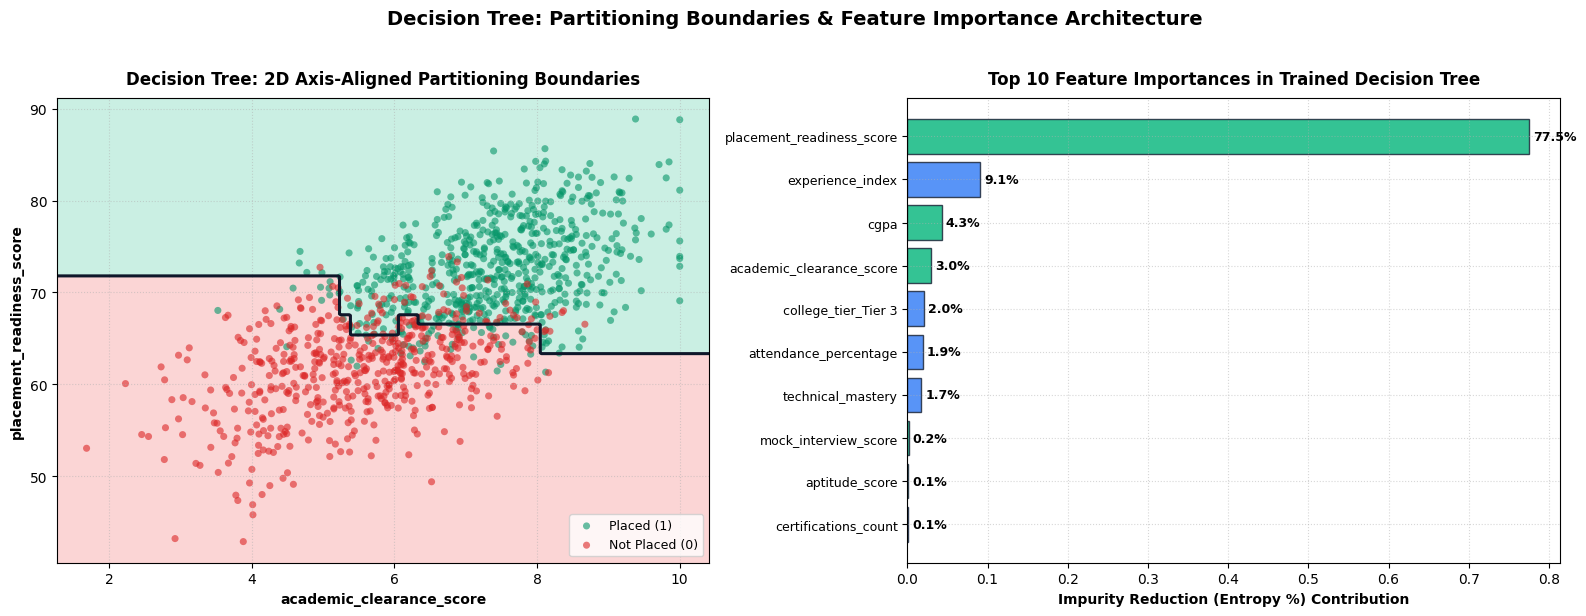

Top 5 Decision Tree Features by Importance:
  1. placement_readiness_score: 77.48%
  2. experience_index: 9.07%
  3. cgpa: 4.26%
  4. academic_clearance_score: 3.01%
  5. college_tier_Tier 3: 2.03%


In [15]:
from sklearn.tree import plot_tree

# ══════════════════════════════════════════════════════════════════════════════
# 1. Decision Tree Graph Structure (Top 3 Depths)
# ══════════════════════════════════════════════════════════════════════════════
plt.figure(figsize=(22, 10))
plot_tree(
    model,
    max_depth=3,
    feature_names=X.columns,
    class_names=['Not Placed', 'Placed'],
    filled=True,
    rounded=True,
    precision=2,
    fontsize=8
)
plt.title('Decision Tree Graph Structure (Root & Top 3 Levels of Trained Model)',
          fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# 2. 2D Recursive Partitioning & Feature Importances
# ══════════════════════════════════════════════════════════════════════════════
np.random.seed(42)
vis_idx = np.random.choice(len(X_test), size=min(1200, len(X_test)), replace=False)

feat1, feat2 = 'academic_clearance_score', 'placement_readiness_score'
X_pair_raw = X.iloc[y_test.index[vis_idx]][[feat1, feat2]].values
y_vis = y_test.iloc[vis_idx].values

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot A: 2D Recursive Partitioning
dt_2d = DecisionTreeClassifier(criterion='entropy', max_depth=6, min_samples_leaf=15, random_state=42)
dt_2d.fit(X_pair_raw, y_vis)

pad1 = 0.05 * (X_pair_raw[:, 0].max() - X_pair_raw[:, 0].min())
pad2 = 0.05 * (X_pair_raw[:, 1].max() - X_pair_raw[:, 1].min())
x_min, x_max = X_pair_raw[:, 0].min() - pad1, X_pair_raw[:, 0].max() + pad1
y_min, y_max = X_pair_raw[:, 1].min() - pad2, X_pair_raw[:, 1].max() + pad2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
Z_dt = dt_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

axes[0].contourf(xx, yy, Z_dt, levels=[-0.5, 0.5, 1.5], alpha=0.22, colors=['#ef4444', '#10b981'])
axes[0].contour(xx, yy, Z_dt, levels=[0.5], colors=['#0f172a'], linewidths=[2.2])
axes[0].scatter(X_pair_raw[y_vis == 1, 0], X_pair_raw[y_vis == 1, 1],
               c='#059669', label='Placed (1)', alpha=0.6, edgecolors='none', s=26)
axes[0].scatter(X_pair_raw[y_vis == 0, 0], X_pair_raw[y_vis == 0, 1],
               c='#dc2626', label='Not Placed (0)', alpha=0.6, edgecolors='none', s=26)

axes[0].set_xlabel(feat1, fontsize=10, fontweight='bold')
axes[0].set_ylabel(feat2, fontsize=10, fontweight='bold')
axes[0].set_title('Decision Tree: 2D Axis-Aligned Partitioning Boundaries', fontsize=12, fontweight='bold', pad=10)
axes[0].legend(loc='lower right', frameon=True, fontsize=9)
axes[0].grid(True, linestyle=':', alpha=0.5)

# Plot B: Feature Importances
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
colors = ['#10b981' if ('score' in f or 'cgpa' in f) else '#3b82f6' for f in importances.index]

axes[1].barh(range(len(importances)), importances.values[::-1], color=colors[::-1], edgecolor='#1e293b', alpha=0.85)
axes[1].set_yticks(range(len(importances)))
axes[1].set_yticklabels(importances.index[::-1], fontsize=9)
for idx, val in enumerate(importances.values[::-1]):
    axes[1].text(val + 0.005, idx, f'{val*100:.1f}%', va='center', fontsize=9, fontweight='bold')
axes[1].set_xlabel('Impurity Reduction (Entropy %) Contribution', fontsize=10, fontweight='bold')
axes[1].set_title('Top 10 Feature Importances in Trained Decision Tree', fontsize=12, fontweight='bold', pad=10)
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.suptitle('Decision Tree: Partitioning Boundaries & Feature Importance Architecture',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Top 5 Decision Tree Features by Importance:")
for rank, (feat, val) in enumerate(importances.head(5).items(), 1):
    print(f"  {rank}. {feat}: {val*100:.2f}%")
